Verifikasi instalasi

In [1]:
import sys
import neo4j
import pandas as pd
import numpy as np
import networkx as nx
import sklearn
import matplotlib.pyplot as plt

print("Python:", sys.version)
print("Lokasi Python:", sys.executable)
print("Neo4j driver:", neo4j.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("NetworkX:", nx.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: 3.13.15 (tags/v3.13.15:4061bc4, Aug  5 2026, 13:05:39) [MSC v.1944 64 bit (AMD64)]
Lokasi Python: c:\Users\Asus\Downloads\007-UTS-GSD\myvenv\Scripts\python.exe
Neo4j driver: 6.4.1
Pandas: 3.0.6
NumPy: 2.5.4
NetworkX: 3.7
Scikit-learn: 1.9.1


Membuat koneksi ke Neo4j

In [2]:
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "fathinah")

In [ ]:
driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Berhasil terhubung ke Neo4j!")

Berhasil terhubung ke Neo4j!


Membuat node dan relationship

In [ ]:
def add_friend(driver, name, friend_name):
    driver.execute_query("""
        MERGE (a:Person {name: $name})
        MERGE (friend:Person {name: $friend_name})
        MERGE (a)-[:KNOWS]->(friend)""",
        name=name,
        friend_name=friend_name,
        database_="neo4j",)

Menampilkan daftar teman

In [ ]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query("""
        MATCH (a:Person)-[:KNOWS]->(friend)
        WHERE a.name = $name
        RETURN friend.name AS friend_name
        ORDER BY friend_name""",
        name=name,
        database_="neo4j",)

    for record in records:
        print(record["friend_name"])

In [6]:
add_friend(driver, "Arthur", "Guinevere")
add_friend(driver, "Arthur", "Lancelot")
add_friend(driver, "Arthur", "Merlin")

print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


In [7]:
driver.close()

# checkpoint pendahuluan #

1. Apa nama database yang digunakan pada tutorial ini? 
Database yang digunakan adalah neo4j, terlihat dari parameter database_="neo4j"

2. Sebutkan akses lain yang dapat digunakan untuk mengakses database lain dalam satu instance.
Kita dapat menentukan database tujuan pada parameter database_ ketika menjalankan query, misalnya database_="nama_database_lain", selama database tersebut tersedia dan pengguna memiliki hak akses. Kita juga dapat menggunakan perintah Cypher untuk manipulasi data, seperti MATCH, CREATE, MERGE, SET, dan DELETE.

3. Apa jenis graf pertemanan yang telah dibuat?
Graf tersebut merupakan graf berarah (directed graph) karena hubungan KNOWS dibuat dari Arthur menuju masing-masing temannya. Relasi itu tidak otomatis berarti temannya mengenal Arthur dalam arah sebaliknya.

# Proses Import Data dari RetailRocket ke Database Neo4J #

Lokasi events.csv

In [8]:

import os

print("Folder kerja:", os.getcwd())
print("Isi folder:")
print(os.listdir("."))


Folder kerja: c:\Users\Asus\Downloads\007-UTS-GSD
Isi folder:
['category_tree.csv', 'Driver.ipynb', 'events.csv', 'import', 'item_properties_part1.csv', 'item_properties_part2.csv', 'myvenv']


Baca dataset

In [ ]:

import pandas as pd

FILE_PATH = "events.csv"  # Sesuaikan jika file ada di folder lain
df = pd.read_csv(FILE_PATH)

print("Ukuran dataset:", df.shape)
print("Kolom:", df.columns.tolist())

display(df.head())


Ukuran dataset: (2756101, 5)
Kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


Periksa kolom dan data

In [10]:

print("Informasi dataset:")
df.info()

print("\nJenis event:")
print(df["event"].value_counts())

print("\nJumlah nilai kosong:")
display(df.isnull().sum())


Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          str    
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), str(1)
memory usage: 105.1 MB

Jenis event:
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

Jumlah nilai kosong:


timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64

Menyiapkan koneksi Neo4j

In [11]:

from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "fathinah")

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

print("Koneksi Neo4j berhasil!")


Koneksi Neo4j berhasil!


membuat constraint

In [12]:

with driver.session(database="neo4j") as session:
    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """)

    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """)

print("Constraint berhasil dibuat!")


Constraint berhasil dibuat!


fungsi impor batch

In [13]:

def import_batch(tx, batch):
    query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row

    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    }
    """
    tx.run(query, batch=batch)


Bersihkan data dan impor

In [14]:

import pandas as pd
from tqdm.auto import tqdm

# Pastikan kolom sesuai dataset
required_columns = [
    "timestamp", "visitorid", "event", "itemid", "transactionid"
]

assert all(col in df.columns for col in required_columns), (
    "Ada kolom dataset yang belum sesuai!"
)

# Ubah nilai kosong menjadi None atau string kosong sesuai kebutuhan
data = df[required_columns].copy()
data = data.dropna(subset=["timestamp", "visitorid", "event", "itemid"])

data["timestamp"] = data["timestamp"].astype("int64")
data["visitorid"] = data["visitorid"].astype("int64")
data["itemid"] = data["itemid"].astype("int64")
data["event"] = data["event"].astype(str)
data["transactionid"] = data["transactionid"].where(
    data["transactionid"].notna(), None
)

batch_size = 5000
total_rows = len(data)

with driver.session(database="neo4j") as session:
    for start in tqdm(range(0, total_rows, batch_size)):
        batch_df = data.iloc[start:start + batch_size]
        records = batch_df.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Selesai mengimpor", total_rows, "baris.")


  0%|          | 0/552 [00:00<?, ?it/s]

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=9, column=5, offset=141>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 141, 'line': 9, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n        WITH v, i, 

Selesai mengimpor 2756101 baris.


Periksa hasil impor

In [15]:

with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH (n)
        RETURN labels(n) AS jenis_node, count(n) AS jumlah
    """)
    for record in result:
        print(record["jenis_node"], record["jumlah"])

    result = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS jenis_relasi, count(r) AS jumlah
        ORDER BY jenis_relasi
    """)
    for record in result:
        print(record["jenis_relasi"], record["jumlah"])


['Person'] 4
['Visitor'] 1407580
['Item'] 235061
ADDED_TO_CART 69332
BOUGHT 22457
KNOWS 3
VIEWED 2664312


# Wrangling dan EDA

### Filter data berdasarkan periode 
p1=24 juni - 4 agustus 2015
p2= 5 agustus - 12 september 2015

In [16]:

import pandas as pd

# Konversi timestamp Unix milidetik ke datetime
df["datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    errors="coerce"
)

# P1: 24 Juni - 4 Agustus 2015
p1 = df[
    (df["datetime"] >= "2015-06-24") &
    (df["datetime"] < "2015-08-05")
].copy()

# P2: 5 Agustus - 12 September 2015
p2 = df[
    (df["datetime"] >= "2015-08-05") &
    (df["datetime"] < "2015-09-13")
].copy()

print("Jumlah data P1 (training):", len(p1))
print("Jumlah data P2 (testing):", len(p2))

print("\nRentang waktu P1:")
print(p1["datetime"].min(), "sampai", p1["datetime"].max())

print("\nRentang waktu P2:")
print(p2["datetime"].min(), "sampai", p2["datetime"].max())


Jumlah data P1 (training): 910377
Jumlah data P2 (testing): 702539

Rentang waktu P1:
2015-06-24 00:00:00.103000 sampai 2015-08-04 23:59:45.149000

Rentang waktu P2:
2015-08-05 00:00:00.700000 sampai 2015-09-12 23:59:47.942000


menyimpan ke csv


In [17]:

p1.to_csv("retailrocket_P1_training.csv", index=False)
p2.to_csv("retailrocket_P2_testing.csv", index=False)

print("File berhasil disimpan:")
print("- retailrocket_P1_training.csv")
print("- retailrocket_P2_testing.csv")


File berhasil disimpan:
- retailrocket_P1_training.csv
- retailrocket_P2_testing.csv


Periksa distribusi event

In [18]:

print("Distribusi event P1:")
display(p1["event"].value_counts())

print("\nDistribusi event P2:")
display(p2["event"].value_counts())


Distribusi event P1:


event
view           880274
addtocart       22607
transaction      7496
Name: count, dtype: int64


Distribusi event P2:


event
view           678214
addtocart       18512
transaction      5813
Name: count, dtype: int64

P1 mencakup periode 24 Juni–4 Agustus 2015, sedangkan P2 mencakup 5 Agustus–12 September 2015.

Dari hasil tersebut, interaksi view paling dominan pada kedua periode. Interaksi transaction jumlahnya lebih sedikit dibandingkan view dan addtocart. Ini bisa menjadi salah satu temuan awal EDA.

### Komposisi Subgraph

Langkah 1 — Buat fungsi untuk menghitung komposisi subgraph

In [19]:

import pandas as pd

def hitung_komposisi(driver, tanggal_mulai, tanggal_akhir):
    # Batas waktu dalam Unix epoch milidetik
    start_ms = int(pd.Timestamp(tanggal_mulai).timestamp() * 1000)
    end_ms = int(pd.Timestamp(tanggal_akhir).timestamp() * 1000)

    query = """
    MATCH (v:Visitor)-[r]->(i:Item)
    WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
      AND r.timestamp >= $start_ms
      AND r.timestamp < $end_ms
    RETURN
        count(DISTINCT v) AS jumlah_visitor,
        count(DISTINCT i) AS jumlah_item,
        count(r) AS jumlah_interaksi,
        sum(CASE WHEN type(r) = 'VIEWED' THEN 1 ELSE 0 END)
            AS jumlah_view,
        sum(CASE WHEN type(r) = 'ADDED_TO_CART' THEN 1 ELSE 0 END)
            AS jumlah_addtocart,
        sum(CASE WHEN type(r) = 'BOUGHT' THEN 1 ELSE 0 END)
            AS jumlah_transaction
    """

    records, _, _ = driver.execute_query(
        query,
        start_ms=start_ms,
        end_ms=end_ms,
        database_="neo4j"
    )

    return records[0].data()


Langkah 2 — Hitung P1 dan P2

In [20]:

hasil_p1 = hitung_komposisi(
    driver, "2015-06-24", "2015-08-05"
)

hasil_p2 = hitung_komposisi(
    driver, "2015-08-05", "2015-09-13"
)

tabel_komposisi = pd.DataFrame(
    [hasil_p1, hasil_p2],
    index=["P1 Training", "P2 Testing"]
)

display(tabel_komposisi)


,jumlah_visitor,jumlah_item,jumlah_interaksi,jumlah_view,jumlah_addtocart,jumlah_transaction
P1 Training,485866,144282,910377,880274,22607,7496
P2 Testing,392099,129908,702539,678214,18512,5813


Langkah 3 — Simpan hasil untuk dokumentasi

In [21]:

tabel_komposisi.to_csv("komposisi_subgraph.csv")
print("Hasil disimpan ke komposisi_subgraph.csv")


Hasil disimpan ke komposisi_subgraph.csv


Query Cypher menggunakan MATCH untuk mencari pola graf dari node Visitor menuju node Item melalui relationship interaksi. Klausa WHERE memfilter relationship berdasarkan jenis dan rentang timestamp yang ditentukan. Fungsi count(DISTINCT v) dan count(DISTINCT i) menghitung pengunjung serta produk unik, sedangkan count(r) menghitung seluruh relationship yang sesuai dengan filter. Selanjutnya, sum(CASE WHEN ...) menghitung jumlah setiap jenis interaksi.

hasil subgraph berdasarkan relationship ini menghitung pengunjung dan produk yang benar-benar berinteraksi dalam periode tersebut, bukan seluruh node yang ada di database.

### Vector Space Modelling (VSM) untuk User

Langkah 1 — Buat matriks User–Item

In [39]:

import pandas as pd
from scipy.sparse import csr_matrix

# Membaca data training
p1 = pd.read_csv("retailrocket_P1_training.csv")

# Mengubah interaksi menjadi bobot
event_weights = {
    "view": 1,
    "addtocart": 2,
    "transaction": 3
}

p1["weight"] = p1["event"].map(event_weights).fillna(0)

# Agregasi jika visitor berinteraksi dengan item yang sama berulang kali
user_item = (
    p1.groupby(["visitorid", "itemid"])["weight"]
      .sum()
      .reset_index()
)

# Membuat matriks sparse User-Item
user_codes, user_ids = pd.factorize(user_item["visitorid"])
item_codes, item_ids = pd.factorize(user_item["itemid"])

user_item_matrix = csr_matrix(
    (
        user_item["weight"].to_numpy(),
        (user_codes, item_codes)
    ),
    shape=(len(user_ids), len(item_ids))
)

print("Jumlah user unik:", len(user_ids))
print("Jumlah item unik:", len(item_ids))
print("Shape matriks User-Item:", user_item_matrix.shape)
print("Jumlah elemen nonzero:", user_item_matrix.nnz)


Jumlah user unik: 485866
Jumlah item unik: 144282
Shape matriks User-Item: (485866, 144282)
Jumlah elemen nonzero: 716896


Langkah 2 — Visualisasi graf User

Jumlah node pada graf sampel: 100
Jumlah edge pada graf sampel: 0


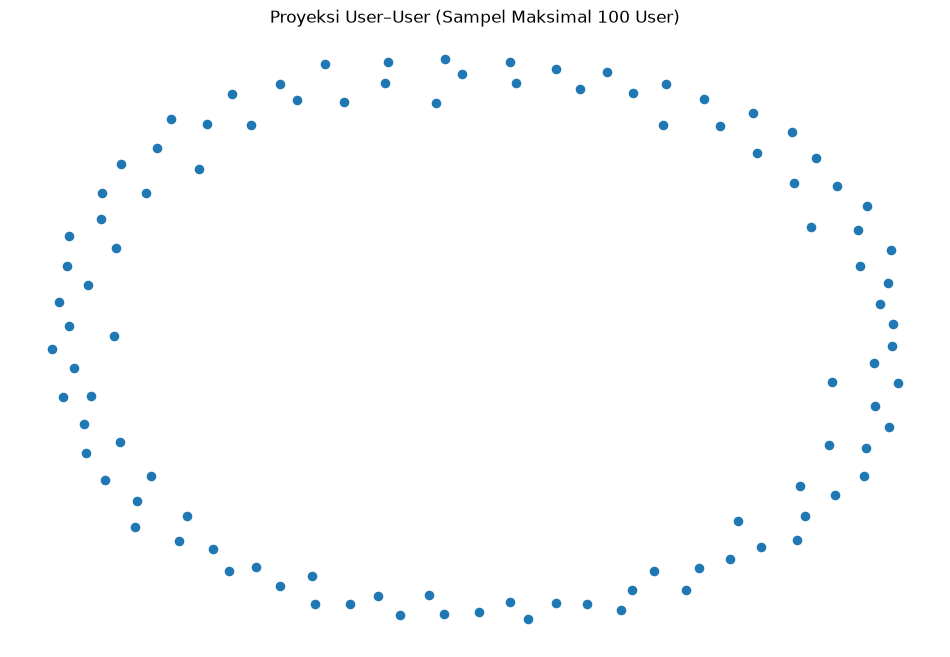

In [40]:

import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from collections import defaultdict

# Ambil maksimal 100 user pertama untuk visualisasi
max_users = 100
sample_users = list(user_ids[:max_users])
sample_set = set(sample_users)

# Item yang berinteraksi dengan masing-masing user
user_items = defaultdict(set)

for row in user_item.itertuples(index=False):
    if row.visitorid in sample_set:
        user_items[row.visitorid].add(row.itemid)

# Bangun proyeksi user-user
G_user = nx.Graph()
G_user.add_nodes_from(sample_users)

item_users = defaultdict(list)

for user, items in user_items.items():
    for item in items:
        item_users[item].append(user)

for users in item_users.values():
    if len(users) > 1:
        for u, v in combinations(users, 2):
            G_user.add_edge(u, v)

print("Jumlah node pada graf sampel:", G_user.number_of_nodes())
print("Jumlah edge pada graf sampel:", G_user.number_of_edges())

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_user, seed=42)
nx.draw_networkx(
    G_user,
    pos,
    node_size=35,
    with_labels=False,
    edge_color="gray"
)
plt.title("Proyeksi User–User (Sampel Maksimal 100 User)")
plt.axis("off")
plt.show()


Vector Space Modelling untuk user dibentuk dengan merepresentasikan setiap visitor sebagai baris dan setiap item sebagai kolom. Nilai matriks merupakan jumlah bobot interaksi visitor terhadap item. Matriks bersifat sparse karena sebagian besar visitor hanya berinteraksi dengan sebagian kecil item. Proyeksi user–user menghubungkan dua visitor apabila keduanya berinteraksi dengan item yang sama.

### Vector Space Modelling (VSM) untuk Item.

Langkah 1 — Membuat matriks Item–User

In [41]:

import pandas as pd
from scipy.sparse import csr_matrix

# Membaca data training
p1 = pd.read_csv("retailrocket_P1_training.csv")

event_weights = {
    "view": 1,
    "addtocart": 2,
    "transaction": 3
}

p1["weight"] = p1["event"].map(event_weights).fillna(0)

# Agregasi bobot interaksi untuk setiap pasangan user-item
item_user = (
    p1.groupby(["itemid", "visitorid"])["weight"]
      .sum()
      .reset_index()
)

# Membentuk matriks sparse Item-User
item_codes, item_ids = pd.factorize(item_user["itemid"])
user_codes, user_ids = pd.factorize(item_user["visitorid"])

item_user_matrix = csr_matrix(
    (
        item_user["weight"].to_numpy(),
        (item_codes, user_codes)
    ),
    shape=(len(item_ids), len(user_ids))
)

print("Jumlah item unik:", len(item_ids))
print("Jumlah user unik:", len(user_ids))
print("Shape matriks Item-User:", item_user_matrix.shape)
print("Jumlah elemen nonzero:", item_user_matrix.nnz)


Jumlah item unik: 144282
Jumlah user unik: 485866
Shape matriks Item-User: (144282, 485866)
Jumlah elemen nonzero: 716896


Langkah 2 — Visualisasi proyeksi Item–Item

Jumlah node graf sampel: 100
Jumlah edge graf sampel: 1


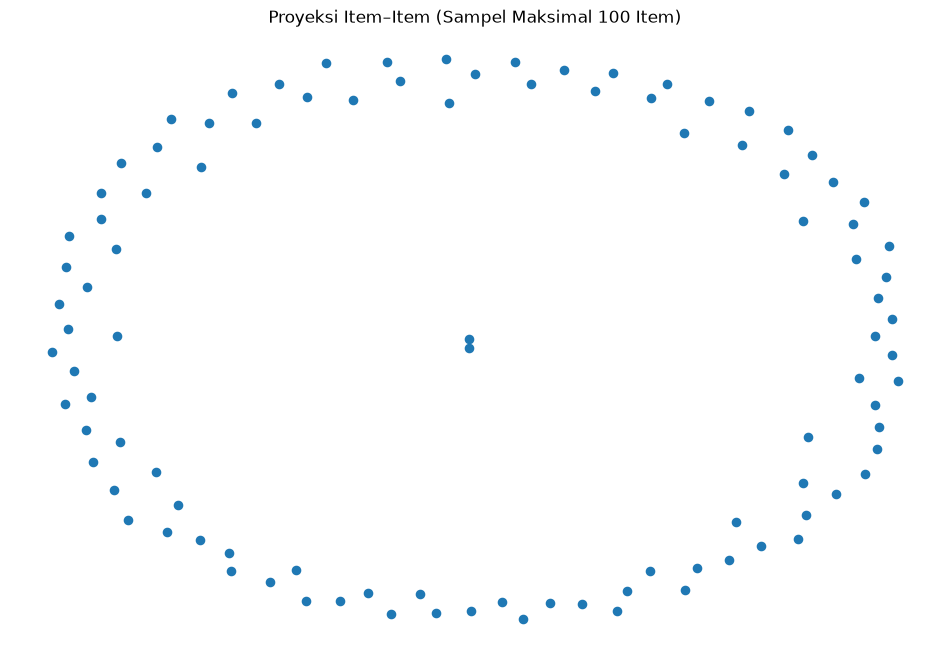

In [42]:

import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from collections import defaultdict

max_items = 100
sample_items = set(item_ids[:max_items])

# Daftar user untuk setiap item pada sampel
item_users = defaultdict(set)

for row in item_user.itertuples(index=False):
    if row.itemid in sample_items:
        item_users[row.itemid].add(row.visitorid)

# Balik indeks menjadi user -> item
user_items = defaultdict(list)

for item, users in item_users.items():
    for user in users:
        user_items[user].append(item)

# Membuat graf proyeksi Item-Item
G_item = nx.Graph()
G_item.add_nodes_from(sample_items)

for items in user_items.values():
    if len(items) > 1:
        for a, b in combinations(items, 2):
            G_item.add_edge(a, b)

print("Jumlah node graf sampel:", G_item.number_of_nodes())
print("Jumlah edge graf sampel:", G_item.number_of_edges())

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_item, seed=42)
nx.draw_networkx(
    G_item,
    pos,
    node_size=35,
    with_labels=False,
    edge_color="gray"
)
plt.title("Proyeksi Item–Item (Sampel Maksimal 100 Item)")
plt.axis("off")
plt.show()


Langkah 3 — Membandingkan VSM User dan Item

In [43]:

print("VSM User-Item")
print("Shape:", user_item_matrix.shape)
print("Nonzero:", user_item_matrix.nnz)

print("\nVSM Item-User")
print("Shape:", item_user_matrix.shape)
print("Nonzero:", item_user_matrix.nnz)


VSM User-Item
Shape: (485866, 144282)
Nonzero: 716896

VSM Item-User
Shape: (144282, 485866)
Nonzero: 716896


VSM Item merepresentasikan setiap item sebagai vektor berdasarkan interaksi user. Baris merepresentasikan item dan kolom merepresentasikan user. Matriks ini bersifat sparse karena setiap item hanya berinteraksi dengan sebagian dari seluruh user. Proyeksi Item–Item menghubungkan item yang pernah diinteraksikan oleh user yang sama.

### Membandingkan proyeksi User–User dan Item–Item

In [44]:
print("=== PROYEKSI USER-USER ===")
print("Node:", G_user.number_of_nodes())
print("Edge:", G_user.number_of_edges())

print("\n=== PROYEKSI ITEM-ITEM ===")
print("Node:", G_item.number_of_nodes())
print("Edge:", G_item.number_of_edges())

print("\n=== SPARSITY MATRIKS ===")
print(
    "User-Item:",
    1 - user_item_matrix.nnz /
    (user_item_matrix.shape[0] * user_item_matrix.shape[1])
)

print(
    "Item-User:",
    1 - item_user_matrix.nnz /
    (item_user_matrix.shape[0] * item_user_matrix.shape[1])
)

=== PROYEKSI USER-USER ===
Node: 100
Edge: 0

=== PROYEKSI ITEM-ITEM ===
Node: 100
Edge: 1

=== SPARSITY MATRIKS ===
User-Item: 0.9999897734888917
Item-User: 0.9999897734888917


Proyeksi User–User berfokus pada kemiripan perilaku pengunjung, sedangkan Item–Item berfokus pada kemiripan produk berdasarkan pola interaksi pengunjung. Efisiensi keduanya ditentukan oleh jumlah entitas, kepadatan koneksi, dan kebutuhan sistem rekomendasi. Untuk rekomendasi produk kepada user, proyeksi Item–Item merupakan kandidat yang relevan karena similarity antarproduk dapat digunakan untuk menemukan produk yang berkaitan dengan riwayat interaksi user.

### Menghitung similarity dengan Python

In [45]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Ambil 100 item pertama dari matriks Item-User
n_sample = min(100, item_user_matrix.shape[0])
sample_matrix = item_user_matrix[:n_sample]

similarity_matrix = cosine_similarity(sample_matrix)

print("Shape matriks similarity:", similarity_matrix.shape)
print("Contoh similarity:")
print(np.round(similarity_matrix[:5, :5], 3))

Shape matriks similarity: (100, 100)
Contoh similarity:
[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]]


Langkah 1 — Hitung similarity untuk seluruh item P1

In [46]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity

# Pastikan item_user_matrix dan item_ids berasal dari VSM P1
# Item acuan dipilih secara acak dengan seed tetap
rng = np.random.default_rng(42)
anchor_idx = int(rng.integers(0, item_user_matrix.shape[0]))

# Ambil vektor item acuan
anchor_vector = item_user_matrix[anchor_idx]

# Hitung cosine similarity dengan semua item secara bertahap
similarities = cosine_similarity(
    anchor_vector,
    item_user_matrix
).ravel()

# Keluarkan item acuan sendiri
similarities[anchor_idx] = -1

# Ambil lima item dengan similarity tertinggi
top_indices = np.argsort(similarities)[::-1][:5]

anchor_item = int(item_ids[anchor_idx])

hasil_similarity = pd.DataFrame({
    "item_id": [int(item_ids[i]) for i in top_indices],
    "similarity": [float(similarities[i]) for i in top_indices]
})

print("Item acuan:", anchor_item)
display(hasil_similarity)


Item acuan: 41731


,item_id,similarity
0,50277,0.447214
1,416783,0.447214
2,193278,0.447214
3,47428,0.447214
4,460294,0.447214


Langkah 2 — Simpan hasil similarity ke Neo4j

In [47]:

query_similarity = """
MATCH (source:Item {itemId: $anchor_id})
MATCH (target:Item {itemId: $target_id})
MERGE (source)-[r:SIMILAR_TO]->(target)
SET r.similarity = $similarity
"""

with driver.session(database="neo4j") as session:
    for row in hasil_similarity.itertuples(index=False):
        session.run(
            query_similarity,
            anchor_id=anchor_item,
            target_id=int(row.item_id),
            similarity=float(row.similarity)
        )

print("Relationship SIMILAR_TO berhasil disimpan.")


Relationship SIMILAR_TO berhasil disimpan.


Langkah 3 — Query lima similarity tertinggi

In [48]:

query_top5 = """
MATCH (source:Item {itemId: $anchor_id})-[r:SIMILAR_TO]->(target:Item)
RETURN
    source.itemId AS item_acuan,
    target.itemId AS item_mirip,
    r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    records = session.run(query_top5, anchor_id=anchor_item)
    display(pd.DataFrame([record.data() for record in records]))


,item_acuan,item_mirip,similarity
0,41731,50277,0.447214
1,41731,47428,0.447214
2,41731,193278,0.447214
3,41731,416783,0.447214
4,41731,460294,0.447214


In [49]:
print("ID item acuan:", anchor_item)

ID item acuan: 41731


Penjelasan Cypher: MATCH mencari item acuan dan relasi SIMILAR_TO. RETURN menampilkan ID item serta nilai similarity. ORDER BY similarity DESC mengurutkan dari nilai terbesar, sedangkan LIMIT 5 membatasi hasil menjadi lima record.

### Analytics

#### Rekomendasi KNN, Hit@5, dan NDCG@5.

Langkah 1 — Pilih user secara acak

In [50]:

import pandas as pd
import numpy as np

p1 = pd.read_csv("retailrocket_P1_training.csv")
p2 = pd.read_csv("retailrocket_P2_testing.csv")

# Pilih user yang muncul di training dan testing
users_p1 = set(p1["visitorid"].unique())
users_p2 = set(p2["visitorid"].unique())
eligible_users = sorted(users_p1 & users_p2)

# Pemilihan acak yang bisa direproduksi
rng = np.random.default_rng(42)
selected_user = int(rng.choice(eligible_users))

print("Jumlah user yang tersedia:", len(eligible_users))
print("User terpilih:", selected_user)


Jumlah user yang tersedia: 18711
User terpilih: 125052


Langkah 2 — Membuat sistem rekomendasi KNN dengan \(k=5\)

In [51]:

import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors

# P1 adalah training, P2 adalah testing
event_weights = {
    "view": 1,
    "addtocart": 2,
    "transaction": 3
}

train = p1.copy()
test = p2.copy()

train["weight"] = train["event"].map(event_weights).fillna(0)
test["weight"] = test["event"].map(event_weights).fillna(0)

# Agregasi bobot interaksi per user-item
interactions = (
    train.groupby(["visitorid", "itemid"], as_index=False)["weight"]
         .sum()
)

# Pemetaan ID asli ke indeks matriks
user_ids = np.sort(interactions["visitorid"].unique())
item_ids = np.sort(interactions["itemid"].unique())

user_to_idx = {u: i for i, u in enumerate(user_ids)}
item_to_idx = {item: i for i, item in enumerate(item_ids)}

rows = interactions["visitorid"].map(user_to_idx).to_numpy()
cols = interactions["itemid"].map(item_to_idx).to_numpy()
values = interactions["weight"].to_numpy(dtype=float)

user_item_matrix = csr_matrix(
    (values, (rows, cols)),
    shape=(len(user_ids), len(item_ids))
)

# Normalisasi agar cosine similarity dapat digunakan secara efisien
normalized_matrix = normalize(user_item_matrix, norm="l2")

print("Shape matriks:", user_item_matrix.shape)
print("Jumlah interaksi unik user-item:", user_item_matrix.nnz)
print("User tersedia:", 125052 in user_to_idx)


Shape matriks: (485866, 144282)
Jumlah interaksi unik user-item: 716896
User tersedia: True


Langkah 3 — Cari lima tetangga terdekat dan rekomendasikan item

In [52]:

selected_user = 125052
k = 5

if selected_user not in user_to_idx:
    raise ValueError("User tidak ditemukan pada data training.")

user_idx = user_to_idx[selected_user]

# Cari 6 user: user itu sendiri + 5 tetangga
knn = NearestNeighbors(
    n_neighbors=k + 1,
    metric="cosine",
    algorithm="brute"
)
knn.fit(normalized_matrix)

distances, indices = knn.kneighbors(
    normalized_matrix[user_idx],
    n_neighbors=k + 1
)

# Hilangkan user itu sendiri
neighbors = []
for distance, idx in zip(distances[0], indices[0]):
    neighbor_id = int(user_ids[idx])
    if neighbor_id != selected_user:
        neighbors.append((neighbor_id, 1 - float(distance)))
    if len(neighbors) == k:
        break

print("Lima tetangga terdekat:")
display(pd.DataFrame(neighbors, columns=["visitorid", "similarity"]))

# Kumpulkan item yang diinteraksikan tetangga
# Skor item = bobot interaksi tetangga x similarity tetangga
scores = {}

for neighbor_id, similarity in neighbors:
    neighbor_idx = user_to_idx[neighbor_id]
    start = user_item_matrix.indptr[neighbor_idx]
    end = user_item_matrix.indptr[neighbor_idx + 1]

    neighbor_items = user_item_matrix.indices[start:end]
    neighbor_values = user_item_matrix.data[start:end]

    for item_idx, weight in zip(neighbor_items, neighbor_values):
        item_id = int(item_ids[item_idx])
        scores[item_id] = scores.get(item_id, 0) + similarity * weight

# Jangan rekomendasikan item yang sudah diinteraksikan user pada P1
seen_items = set(
    train.loc[train["visitorid"] == selected_user, "itemid"].astype(int)
)

recommendation_scores = {
    item: score
    for item, score in scores.items()
    if item not in seen_items
}

top_recommendations = sorted(
    recommendation_scores.items(),
    key=lambda x: (-x[1], x[0])
)[:5]

recommendations = pd.DataFrame(
    top_recommendations,
    columns=["itemid", "score"]
)

print("Lima rekomendasi untuk user:", selected_user)
display(recommendations)

print("Tiga item rekomendasi teratas:")
display(recommendations.head(3))


Lima tetangga terdekat:


,visitorid,similarity
0,1246343,1.0
1,1230976,1.0
2,1212958,1.0
3,1135919,1.0
4,1024668,1.0


Lima rekomendasi untuk user: 125052


,itemid,score


Tiga item rekomendasi teratas:


,itemid,score


Langkah 4 — Evaluasi Hit@5 dan NDCG@5

In [53]:

# Item relevan pada P2 untuk user yang dipilih
relevant_items = set(
    test.loc[
        (test["visitorid"] == selected_user) &
        (test["event"].isin(["addtocart", "transaction"])),
        "itemid"
    ].astype(int)
)

recommended_items = recommendations["itemid"].astype(int).tolist()
top5 = recommended_items[:5]

# Hit@5: 1 jika ada setidaknya satu item relevan di top 5
hits = [1 if item in relevant_items else 0 for item in top5]
hit_at_5 = int(sum(hits) > 0)

# DCG@5 dan NDCG@5
discounts = 1 / np.log2(np.arange(2, len(top5) + 2))
dcg_at_5 = float(np.sum(np.array(hits) * discounts))

ideal_hits_count = min(len(relevant_items), len(top5))
ideal_hits = np.ones(ideal_hits_count)

idcg_at_5 = float(np.sum(
    ideal_hits / np.log2(np.arange(2, ideal_hits_count + 2))
))

ndcg_at_5 = dcg_at_5 / idcg_at_5 if idcg_at_5 > 0 else 0.0

print("User:", selected_user)
print("Jumlah item relevan di P2:", len(relevant_items))
print("Item rekomendasi top-5:", top5)
print("Item relevan yang ditemukan:", sorted(set(top5) & relevant_items))
print("Hit@5:", hit_at_5)
print("NDCG@5:", round(ndcg_at_5, 4))


User: 125052
Jumlah item relevan di P2: 0
Item rekomendasi top-5: []
Item relevan yang ditemukan: []
Hit@5: 0
NDCG@5: 0.0


Periksa hasil rekomendasi

In [54]:

print("User:", selected_user)
print("\nTetangga terdekat:")
display(pd.DataFrame(neighbors, columns=["visitorid", "similarity"]))

print("\nLima item rekomendasi:")
display(recommendations)

print("\nJumlah item relevan pada P2:", len(relevant_items))
print("Hit@5:", hit_at_5)
print("NDCG@5:", round(ndcg_at_5, 4))


User: 125052

Tetangga terdekat:


,visitorid,similarity
0,1246343,1.0
1,1230976,1.0
2,1212958,1.0
3,1135919,1.0
4,1024668,1.0



Lima item rekomendasi:


,itemid,score



Jumlah item relevan pada P2: 0
Hit@5: 0
NDCG@5: 0.0


Simpan hasil Analytics 

In [55]:

# Simpan rekomendasi dan evaluasi ke CSV
recommendations.to_csv("hasil_rekomendasi_knn.csv", index=False)

hasil_evaluasi = pd.DataFrame([{
    "visitorid": selected_user,
    "k": 5,
    "jumlah_item_relevan_P2": len(relevant_items),
    "jumlah_rekomendasi_relevan": len(
        set(recommendations["itemid"].astype(int)) & relevant_items
    ),
    "Hit@5": hit_at_5,
    "NDCG@5": ndcg_at_5
}])

hasil_evaluasi.to_csv("hasil_evaluasi_knn.csv", index=False)

display(hasil_evaluasi)
print("Hasil disimpan ke CSV.")


,visitorid,k,jumlah_item_relevan_P2,jumlah_rekomendasi_relevan,Hit@5,NDCG@5
0,125052,5,0,0,0,0.0


Hasil disimpan ke CSV.


Sistem rekomendasi menggunakan pendekatan User-Based KNN dengan \(k=5\). User dipilih secara acak menggunakan seed 42 sehingga proses pemilihan dapat direproduksi. Data periode P1 digunakan untuk membentuk profil interaksi dan mencari lima tetangga terdekat, sedangkan P2 digunakan sebagai data pengujian. Rekomendasi dievaluasi menggunakan Hit@5 dan NDCG@5 berdasarkan item relevan pada periode testing.